# 06 · Four input fields: raw forecasts vs ours vs MET Nordic

**Inputs.** Every model enters with the same four fields: 10 m wind (10u, 10v), mean sea-level
pressure (msl) and 2 m temperature (2t).

**Compared.**
* the four raw forecasts: IFS, AIFS (0.25°, bilinear at the stations), MEPS, AROME-Arctic (2.5 km,
  nearest cell);
* **ours**: the dual-scale GNO (SFNO global + FNO regional encoders, width 16, 8 × 16 modes, GNO
  readout 60 / 10 km, zero-initialised MLP head), trained on the four-field inputs of all four models;
  3 seeds × 5 spatial folds, each station predicted by the fold that did not train on it;
* the MET Nordic 1 km analysis at the valid time (bilinear at the stations).

**Score.** Vector RMSE (m/s) of the 10 m wind against the observations at the held-out stations, every
forecast on the same samples (test runs where all four models, the observation and the MET Nordic
analysis exist). Curves: ours is the seed-mean forecast. Overall: RMSE over all lead times; for ours
the mean ± s.d. of the three seeds' RMSE.

| period | train | validation | test |
|---|---|---|---|
| original | 2024-03-01 – 2024-12-31 | 2025-01-01 – 03-31 | 2025-04-01 – 09-12 |
| extended | 2024-03-01 – 2025-12-31 | 2026-01-01 – 03-31 | 2026-04-01 – 11-14 |

In [1]:
import sys
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from pathlib import Path
sys.path.insert(0, '../scripts/report_unified_inputs')
import duallib as D
from station_results import metnordic_at_stations

ORANGE, INK, INK2 = '#eb6834', '#0b0b0b', '#52514e'
MM = 1 / 25.4
FIG = Path('figs/06'); FIG.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({
    'figure.dpi': 220, 'savefig.dpi': 600, 'figure.facecolor': 'white', 'savefig.facecolor': 'white',
    'font.family': 'sans-serif', 'font.sans-serif': ['Arial', 'Liberation Sans', 'DejaVu Sans'],
    'font.size': 7, 'axes.labelsize': 7, 'xtick.labelsize': 6.5, 'ytick.labelsize': 6.5, 'legend.fontsize': 6.5,
    'axes.linewidth': .6, 'xtick.major.width': .6, 'ytick.major.width': .6, 'xtick.major.size': 2.5,
    'ytick.major.size': 2.5, 'axes.spines.top': False, 'axes.spines.right': False, 'legend.frameon': False,
    'lines.linewidth': 1.2, 'pdf.fonttype': 42, 'svg.fonttype': 'none'})

def save(fig, name):
    fig.savefig(FIG / f'{name}.pdf', bbox_inches='tight')
    fig.savefig(FIG / f'{name}.png', bbox_inches='tight')

OURS = f'rg60_rr10_{D.SMALL}_head-mlp'            # dual-scale GNO, four fields
# name: (colour, line style, marker)
STYLE = {'IFS': ('#2a78d6', '-', None), 'AIFS': ('#1baf7a', '-', None),
         'MEPS': ('#9b59b6', '-', None), 'AROME-Arctic': ('#c8a400', '-', None),
         'MET Nordic analysis': (INK2, (0, (4, 1.5)), None), 'ours': (ORANGE, '-', 'o')}

PER = {}
for per in ('original', 'extended'):
    P = D.Period(per)
    mn = metnordic_at_stations(P)
    P.mask &= np.isfinite(mn).all(-1)               # samples with a MET Nordic analysis
    seeds = P.seeds(P.dual, OURS)
    F = {'IFS': P.raw['ifs'], 'AIFS': P.raw['aifs'], 'MEPS': P.raw['meps'], 'AROME-Arctic': P.raw['arome'],
         'MET Nordic analysis': mn, 'ours': np.mean(list(seeds.values()), 0)}
    PER[per] = dict(P=P, F=F, seeds=seeds)
    print(f'{per}: {P.mask.sum():,} samples, {P.mask.any((1, 2)).sum()} runs, '
          f'{P.mask.any((0, 1)).sum()} stations, {len(seeds)} seeds of ours')

original: 367,427 samples, 328 runs, 98 stations, 3 seeds of ours


extended: 509,729 samples, 452 runs, 97 stations, 3 seeds of ours


## 1 · RMSE by lead time

The two periods are scored separately: the extended training period (2024-03 – 2025-12) contains the
original test months, so the two are not independent experiments.

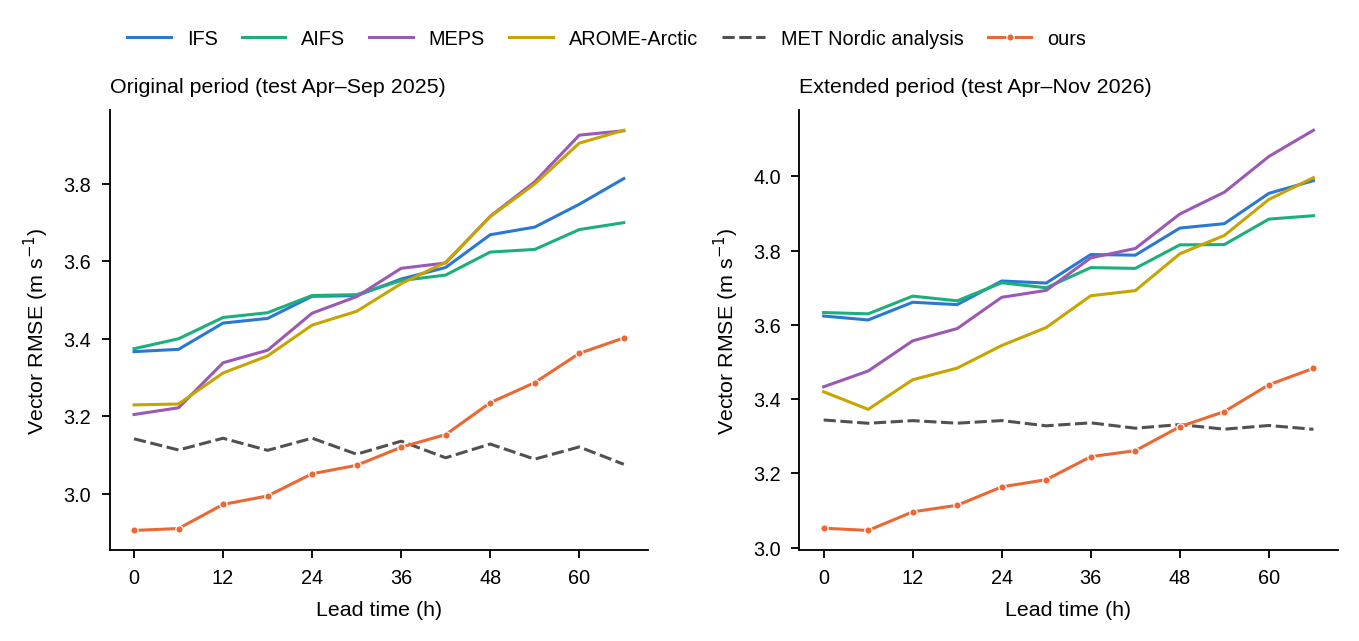

In [2]:
LEADS = PER['original']['P'].leads
PTITLE = {'original': 'Original period (test Apr–Sep 2025)', 'extended': 'Extended period (test Apr–Nov 2026)'}
LEAD = {per: pd.DataFrame({k: d['P'].rmse_lead(d['F'][k]) for k in STYLE}, index=pd.Index(LEADS, name='lead (h)'))
        for per, d in PER.items()}

fig, axs = plt.subplots(1, 2, figsize=(183 * MM, 66 * MM), gridspec_kw=dict(wspace=.28))
for ax, (per, lt) in zip(axs, LEAD.items()):
    for k, (col, ls, mk) in STYLE.items():
        ax.plot(LEADS, lt[k], color=col, ls=ls, marker=mk, ms=2.4, mec='white', mew=.4, lw=1.0, label=k)
    ax.set(xlabel='Lead time (h)', ylabel='Vector RMSE (m s$^{-1}$)', xticks=LEADS[::2])
    ax.set_title(PTITLE[per], fontsize=7, loc='left')
axs[0].legend(ncol=6, loc='lower left', bbox_to_anchor=(0, 1.1), handlelength=2.2, columnspacing=1.2)
save(fig, 'fig1a_rmse_lead')
plt.show()

**Fig. 1a | RMSE by lead time.** Vector RMSE against the station observations of the four raw
forecasts, ours (seed-mean forecast) and the MET Nordic analysis, per test period. MET Nordic is
valid at the observation time, so it has no lead time.

## 2 · RMSE over all lead times

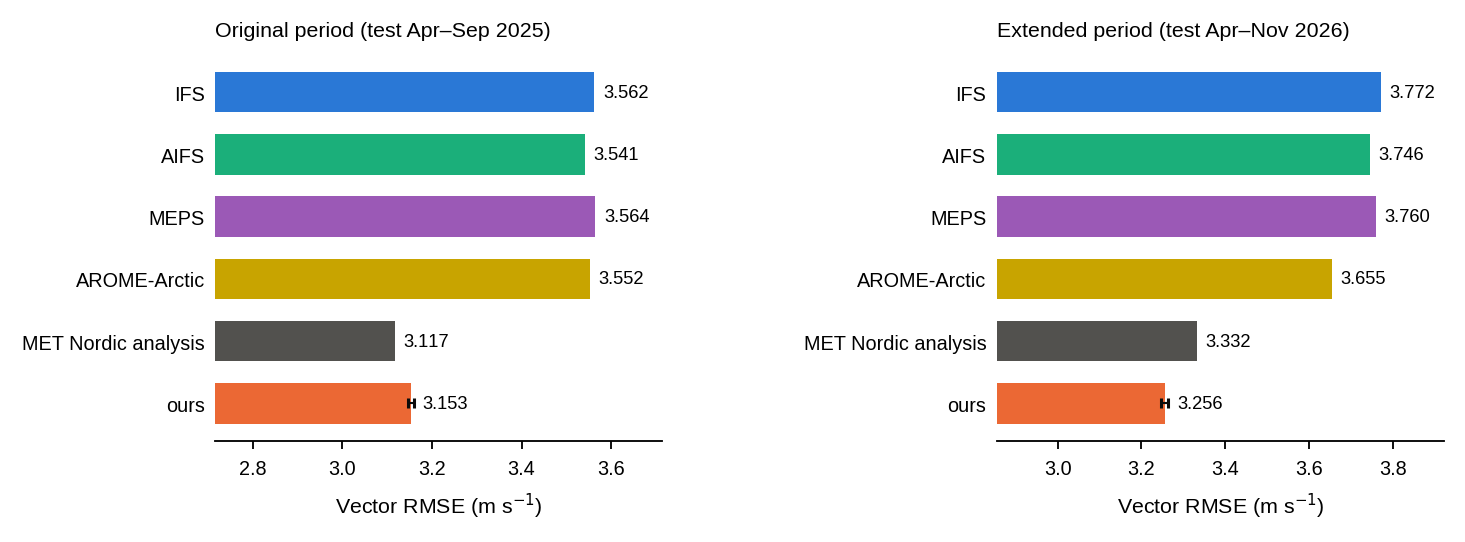

RMSE, all leads  seed s.d.
period   forecast                                       
original IFS                            3.562        NaN
         AIFS                           3.541        NaN
         MEPS                           3.564        NaN
         AROME-Arctic                   3.552        NaN
         MET Nordic analysis            3.117        NaN
         ours                           3.153      0.007
extended IFS                            3.772        NaN
         AIFS                           3.746        NaN
         MEPS                           3.760        NaN
         AROME-Arctic                   3.655        NaN
         MET Nordic analysis            3.332        NaN
         ours                           3.256      0.009

In [3]:
rows = []
for per, d in PER.items():
    P = d['P']
    for k in STYLE:
        if k == 'ours':
            v = np.array([P.rmse(f) for f in d['seeds'].values()])
            rows.append({'period': per, 'forecast': k, 'RMSE, all leads': v.mean(), 'seed s.d.': v.std()})
        else:
            rows.append({'period': per, 'forecast': k, 'RMSE, all leads': P.rmse(d['F'][k]), 'seed s.d.': np.nan})
tab = pd.DataFrame(rows).set_index(['period', 'forecast'])

fig, axs = plt.subplots(1, 2, figsize=(183 * MM, 58 * MM), gridspec_kw=dict(wspace=.75))
names = list(STYLE)
for ax, per in zip(axs, PER):
    t = tab.loc[per]
    for y, k in enumerate(names[::-1]):
        r, sd = t.loc[k, 'RMSE, all leads'], t.loc[k, 'seed s.d.']
        ax.barh(y, r, color=STYLE[k][0], height=.65)
        if np.isfinite(sd):
            ax.errorbar(r, y, xerr=sd, fmt='none', ecolor=INK, elinewidth=.7, capsize=1.5, zorder=4)
        ax.text(r + (sd if np.isfinite(sd) else 0) + .02, y, f'{r:.3f}', va='center', fontsize=6)
    ax.set_yticks(range(len(names)), names[::-1])
    ax.tick_params(axis='y', length=0); ax.spines['left'].set_visible(False)
    ax.set_xlim(t['RMSE, all leads'].min() - .4, t['RMSE, all leads'].max() + .15)
    ax.set_xlabel('Vector RMSE (m s$^{-1}$)')
    ax.set_title(PTITLE[per], fontsize=7, loc='left')
save(fig, 'fig1b_rmse_total')
plt.show()
tab.round(3).to_csv(FIG / 'rmse_total.csv')
for per, lt in LEAD.items():
    lt.round(3).to_csv(FIG / f'rmse_lead_{per}.csv')
tab.round(3)

**Fig. 1b | RMSE over all lead times,** per test period. Ours: mean of the three seeds' RMSE, error
bar: s.d. over the seeds.

Table by lead time:

In [4]:
pd.concat(LEAD, axis=1).round(3)

original                                                        \
              IFS   AIFS   MEPS AROME-Arctic MET Nordic analysis   ours   
lead (h)                                                                  
0           3.367  3.374  3.205        3.229               3.142  2.906   
6           3.373  3.400  3.222        3.232               3.113  2.911   
12          3.440  3.455  3.338        3.312               3.143  2.973   
18          3.452  3.467  3.370        3.356               3.112  2.995   
24          3.509  3.512  3.466        3.435               3.144  3.052   
30          3.511  3.514  3.509        3.471               3.102  3.074   
36          3.554  3.550  3.582        3.542               3.136  3.120   
42          3.584  3.564  3.595        3.597               3.093  3.153   
48          3.668  3.624  3.716        3.715               3.128  3.235   
54          3.688  3.630  3.805        3.799               3.090  3.287   
60          3.747  3.682  3.925        3.904               3.121  3.362   
66          3.813  3.699  3.936        3.938               3.076  3.402   

         extended                                                        
              IFS   AIFS   MEPS AROME-Arctic MET Nordic analysis   ours  
lead (h)                                                                 
0           3.624  3.633  3.433        3.420               3.344  3.052  
6           3.613  3.630  3.476        3.372               3.335  3.046  
12          3.661  3.677  3.557        3.452               3.342  3.096  
18          3.654  3.665  3.590        3.483               3.335  3.114  
24          3.718  3.713  3.674        3.544               3.342  3.164  
30          3.712  3.700  3.693        3.593               3.328  3.183  
36          3.789  3.754  3.780        3.678               3.336  3.245  
42          3.788  3.752  3.806        3.692               3.322  3.261  
48          3.861  3.815  3.898        3.791               3.331  3.326  
54          3.873  3.816  3.957        3.841               3.319  3.366  
60          3.954  3.885  4.053        3.938               3.329  3.439  
66          3.988  3.894  4.124        3.996               3.319  3.483

## 3 · Wind field of one case: ours against the four-model mean, MEPS and MET Nordic

One test run of the original period, drawn at random (seed 2026) among the runs with at least 60
stations observed at +24 h: init 2025-08-19 12 UTC, valid +24 h; on the 1 km MET Nordic grid over
Troms / Senja (land cells, every 2nd cell). Three references, each with its own purpose:

| reference | purpose |
|---|---|
| four-model mean | the baseline ours corrects: what ours changes |
| MEPS (2.5 km) | the regional high-resolution forecast: how the spatial structure differs |
| MET Nordic (1 km) | the high-resolution analysis: how close the spatial structure is |

**(a)–(d)** 10 m wind speed (shared colour scale); **(e)** the magnitude of the correction ours learns,
$\lVert\Delta\mathbf u(x)\rVert$ with $\Delta\mathbf u(x) = \hat{\mathbf u}(x) - \bar{\mathbf f}(x)$;
**(f)** terrain height of the 1 km cells. Circles: station observations at the valid time on the same
speed scale. Inputs to ours are built at every cell as at a station; ours on the grid is the mean of
the 5 fold models and 3 seeds (`scripts/eval_metnordic_grid.py --configs all`,
ROOT/results/metnordic/grid_case_2025-08-19T12.npz, `--case-init 2025-08-19T12`). At the stations every forecast is the held-out one (each
station predicted by the fold that did not train on it).

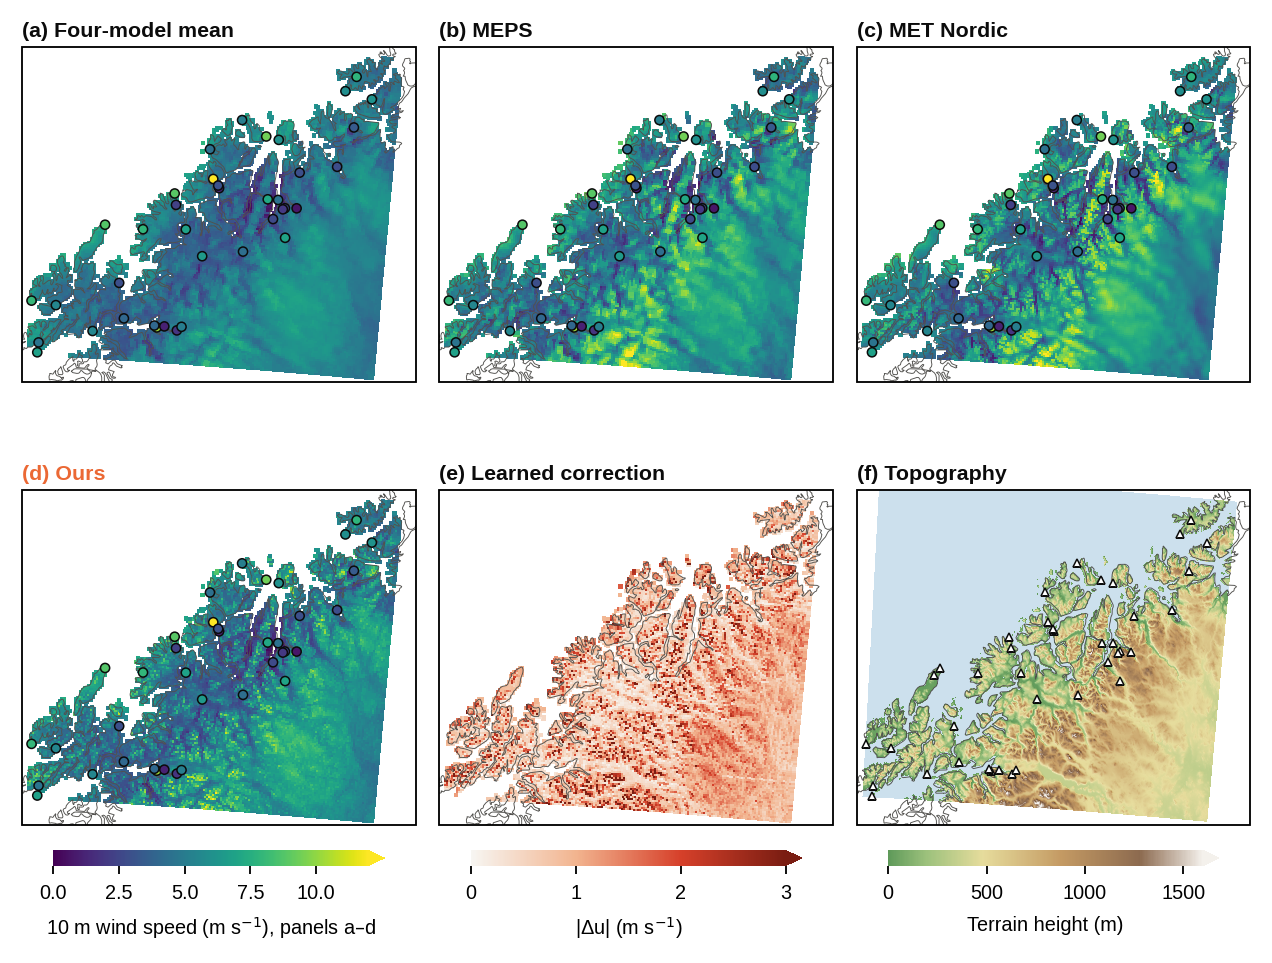

['fig2a_four_model_mean.png', 'fig2b_meps.png', 'fig2c_met_nordic.png', 'fig2d_ours.png', 'fig2e_learned_correction.png', 'fig2f_topography.png']


In [5]:
import cartopy.crs as ccrs
from matplotlib.colors import LinearSegmentedColormap
G = np.load(D.ROOT / 'results' / 'metnordic' / 'grid_case_2025-08-19T12.npz', allow_pickle=True)
init = pd.Timestamp(str(G['case_init'])); valid = init + pd.Timedelta(hours=24)
lon, lat = G['lon'], G['lat']
truth, base, meps, ours = (G['case_truth'], G['case_pred_four_mean'], G['case_pred_raw_meps'],
                           G['case_pred_dual_small_mlp'])
speed = lambda uv: np.linalg.norm(uv, axis=-1)
rm = lambda uv: np.sqrt(np.mean(np.sum((uv - truth) ** 2, -1)))
du = ours - base
dmag = speed(du)
C = np.load(D.ROOT / 'cache' / f"multimodel_{D.PERIODS['original']['tag']}.npz", allow_pickle=True)
olon, olat = C['lon_st'][:D.N_NO], C['lat_st'][:D.N_NO]

# the same case at the stations: observation at the valid time and the held-out station forecasts
P0, F0 = PER['original']['P'], PER['original']['F']
n0, j0 = P0.inits.get_loc(init), list(P0.leads).index(24)
obs_c = P0.obs[n0, j0]                                            # (99, 2)
st_ok = np.isfinite(obs_c).all(-1) & G['st_in']                    # stations inside the grid with an observation
ST = {'IFS': F0['IFS'], 'AIFS': F0['AIFS'], 'MEPS': F0['MEPS'], 'AROME-Arctic': F0['AROME-Arctic'],
      'Four-model mean': P0.base['mix'], 'Ours': F0['ours'], 'MET Nordic analysis': F0['MET Nordic analysis']}
ST = {k: v[n0, j0] for k, v in ST.items()}
st_rm = lambda f: np.sqrt(np.mean(np.sum((f[st_ok] - obs_c[st_ok]) ** 2, -1)))

proj = ccrs.LambertConformal(central_longitude=float(np.median(lon)), central_latitude=float(np.median(lat)))
pc = ccrs.PlateCarree()
vmax = np.ceil(np.nanpercentile(speed(truth), 99.5))
arrow = ((G['mn_x'] - G['mn_x'].min()) % 20 == 0) & ((G['mn_y'] - G['mn_y'].min()) % 20 == 0)
cmag = LinearSegmentedColormap.from_list('mag', ['#f7f6f2', '#f2b48f', '#d6402a', '#7a1d12'])
import xarray as xr
from matplotlib.colors import LightSource, Normalize
from matplotlib.cm import ScalarMappable
# hypsometric tints: lowland green, upland ochre, mountain brown, summits white
terr = LinearSegmentedColormap.from_list('hyps', [(0, '#5f9a5a'), (.12, '#9cc17c'), (.3, '#e6dc9c'),
                                                  (.55, '#c49a63'), (.8, '#8c6a4f'), (1, '#f4f1ec')])
tnorm = Normalize(0, 1600)
SEA = np.array([.80, .88, .93])
TS = xr.open_dataset(D.ROOT / 'metnordic' / 'static.nc')           # the full 1 km MET Nordic grid
t_lon, t_lat = TS.longitude.values, TS.latitude.values
t_alt = np.clip(TS.altitude.values, 0, None)
t_land = TS.land_area_fraction.values > .5

from matplotlib.colors import ListedColormap
_rgb = LightSource(azdeg=315, altdeg=40).shade(t_alt, cmap=terr, norm=tnorm, vert_exag=.02, dx=1000, dy=1000,
                                               blend_mode='soft')[..., :3]
_rgb[~t_land] = SEA
_cell_cmap = ListedColormap(_rgb.reshape(-1, 3))     # one colour per cell: the shaded terrain as a mesh

def terrain(ax):
    # 1 km terrain with hill shading (light from the north-west); sea in light blue
    ax.pcolormesh(t_lon, t_lat, np.arange(t_alt.size).reshape(t_alt.shape), cmap=_cell_cmap,
                  vmin=-.5, vmax=t_alt.size - .5, shading='nearest', transform=pc, rasterized=True)
    return ScalarMappable(norm=tnorm, cmap=terr)
U = 'm s$^{-1}$'
MS = 1.9                                              # marker area (pt²) at 61 mm panel width

def winds(ax, uv, ms):
    ws = speed(uv)
    im = ax.scatter(lon, lat, c=ws, s=ms, marker='s', cmap='viridis', vmin=0, vmax=vmax, linewidths=0,
                    transform=pc, rasterized=True)
    ws_o = speed(obs_c[st_ok])                        # station observations
    ax.scatter(olon[st_ok], olat[st_ok], c=ws_o, s=9 * ms / MS, cmap='viridis', vmin=0, vmax=vmax,
               edgecolors=INK, linewidths=.5, transform=pc, zorder=5)
    return im

PANELS = [('a', 'Four-model mean', base), ('b', 'MEPS', meps), ('c', 'MET Nordic', truth), ('d', 'Ours', ours),
          ('e', 'Learned correction', 'du'), ('f', 'Topography', 'terrain')]

def draw(ax, lab, ttl, what, ms=MS):
    # one panel; returns (mappable, colour-bar label)
    if isinstance(what, np.ndarray):
        m, cl = winds(ax, what, ms), f'10 m wind speed ({U})'
    elif what == 'du':
        m = ax.scatter(lon, lat, c=dmag, s=ms, marker='s', cmap=cmag, vmin=0, vmax=np.ceil(np.percentile(dmag, 98)),
                       linewidths=0, transform=pc, rasterized=True)
        cl = f'|Δu| ({U})'
    else:
        m, cl = terrain(ax), 'Terrain height (m)'
        ax.plot(olon[G['st_in']], olat[G['st_in']], '^', ms=2.4 * np.sqrt(ms / MS), mfc='white', mec=INK, mew=.5,
                transform=pc)
    ax.coastlines(resolution='10m', linewidth=.3, color=INK2)
    ax.set_extent([lon.min() - .1, lon.max() + .1, lat.min() - .05, lat.max() + .05], crs=pc)
    ax.text(0, 1.02, f'({lab}) {ttl}', transform=ax.transAxes, fontsize=7, va='bottom', fontweight='bold',
            color=ORANGE if lab == 'd' else INK)
    return m, cl

def cbar(fig, ax, m, label):
    cb = fig.colorbar(m, cax=ax.inset_axes([.08, -.12, .84, .045]), orientation='horizontal', extend='max')
    cb.set_label(label, fontsize=6.5); cb.outline.set_visible(False)

# the full figure
fig, axs = plt.subplots(2, 3, figsize=(183 * MM, 128 * MM), subplot_kw=dict(projection=proj),
                        gridspec_kw=dict(wspace=.06, hspace=.08))
out = {lab: draw(ax, lab, ttl, what) for ax, (lab, ttl, what) in zip(axs.flat, PANELS)}
cbar(fig, axs[1, 0], out['d'][0], out['d'][1] + ', panels a–d')
cbar(fig, axs[1, 1], *out['e']); cbar(fig, axs[1, 2], *out['f'])
save(fig, 'fig2_wind_maps')
plt.show()

# every panel as its own figure (89 mm, single column), with its colour bar, for the report
SUB = FIG / 'fig2_panels'; SUB.mkdir(exist_ok=True)
for lab, ttl, what in PANELS:
    f1, ax = plt.subplots(figsize=(89 * MM, 72 * MM), subplot_kw=dict(projection=proj))
    m, cl = draw(ax, lab, ttl, what, ms=MS * (89 / 61) ** 2)
    cbar(f1, ax, m, cl)
    name = f"fig2{lab}_{ttl.lower().replace(' ', '_').replace('-', '_')}"
    f1.savefig(SUB / f'{name}.pdf', bbox_inches='tight'); f1.savefig(SUB / f'{name}.png', bbox_inches='tight')
    plt.close(f1)
print(sorted(p_.name for p_ in SUB.glob('*.png')))

**Fig. 2 | Wind field of one case.** +24 h forecasts valid 2025-08-20 12 UTC on the 1 km MET Nordic
grid (land cells). **a**, four-model mean (the baseline ours corrects); **b**, MEPS (2.5 km regional
forecast); **c**, MET Nordic analysis (1 km); **d**, ours; colour: wind speed (shared scale); circles:
station observations on the same scale. **e**, magnitude of the correction ours learns; **f**, terrain
height. MET Nordic is built on MEPS, so it is not independent of the regional models.

RMSE of the same case against MET Nordic over the map and against the observations at the stations
inside the grid (held-out station forecasts):

In [6]:
GRID = {'Four-model mean': base, 'MEPS': meps, 'Ours': ours}
tab_case = pd.DataFrame({
    'RMSE vs MET Nordic, grid (m/s)': {k: rm(GRID[k]) if k in GRID else np.nan for k in ST},
    'RMSE at stations (m/s)': {k: st_rm(f) for k, f in ST.items()},
    'mean speed at stations (m/s)': {k: speed(f[st_ok]).mean() for k, f in ST.items()}})
tab_case.loc['observed'] = [np.nan, 0.0, speed(obs_c[st_ok]).mean()]
print(f'{st_ok.sum()} stations inside the grid with an observation at {valid:%Y-%m-%d %H} UTC')
tab_case.round(2)

39 stations inside the grid with an observation at 2025-08-20 12 UTC


,"RMSE vs MET Nordic, grid (m/s)",RMSE at stations (m/s),mean speed at stations (m/s)
IFS,NaN,3.96,4.46
AIFS,NaN,3.93,4.10
MEPS,1.92,4.21,5.60
AROME-Arctic,NaN,4.20,5.38
Four-model mean,2.02,3.83,4.81
Ours,1.80,3.57,5.01
MET Nordic analysis,NaN,3.63,5.18
observed,NaN,0.00,5.23


## 4 · Where on the grid ours is closer to MET Nordic

Per 1 km point, over the whole original test period: RMSE change against MET Nordic of ours vs each
raw model (blue: ours closer to MET Nordic). Triangles: stations inside the grid. Note that MET Nordic
is built on MEPS, so it is not independent of the regional models.

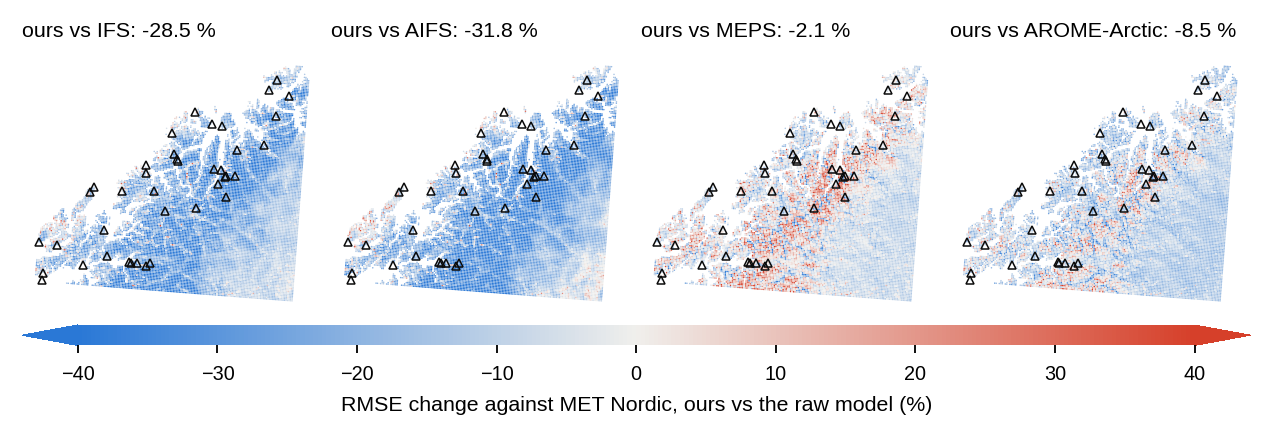

,"RMSE vs MET Nordic, grid (m/s)"
IFS,2.907
AIFS,3.051
MEPS,2.125
AROME-Arctic,2.274
ours,2.080


In [7]:
from matplotlib.colors import LinearSegmentedColormap, TwoSlopeNorm
G = np.load(D.ROOT / 'results' / 'metnordic' / 'grid_eval_all.npz', allow_pickle=True)   # whole test period
cnt = G['cnt_pt']
per_pt = lambda k: np.sqrt(G[f'se_pt_{k}'] / np.maximum(cnt, 1))
tot_g = lambda k: np.sqrt(G[f'se_pt_{k}'].sum() / cnt.sum())
xy, sxy, sin_ = G['xy'], G['st_xy'], G['st_in']
cmap = LinearSegmentedColormap.from_list('div', ['#2a78d6', '#f0efec', '#d6402a'])
norm = TwoSlopeNorm(vcenter=0, vmin=-40, vmax=40)
fig, axs = plt.subplots(1, 4, figsize=(183 * MM, 62 * MM), gridspec_kw=dict(wspace=.03))
for ax, (m, lab) in zip(axs, [('ifs', 'IFS'), ('aifs', 'AIFS'), ('meps', 'MEPS'), ('arome', 'AROME-Arctic')]):
    c = 100 * (per_pt('dual_small_mlp') / per_pt(f'raw_{m}') - 1)
    sc = ax.scatter(xy[:, 0], xy[:, 1], c=c, s=.25, cmap=cmap, norm=norm, linewidths=0, rasterized=True)
    ax.plot(sxy[sin_, 0], sxy[sin_, 1], '^', ms=2.6, mfc='none', mec=INK, mew=.5)
    ax.set_aspect('equal'); ax.set_xticks([]); ax.set_yticks([])
    for sp_ in ax.spines.values():
        sp_.set_visible(False)
    ax.set_title(f"ours vs {lab}: {100 * (tot_g('dual_small_mlp') / tot_g(f'raw_{m}') - 1):+.1f} %",
                 fontsize=7, loc='left')
cb = fig.colorbar(sc, ax=axs, orientation='horizontal', fraction=.05, pad=.03, aspect=60, extend='both')
cb.set_label('RMSE change against MET Nordic, ours vs the raw model (%)')
cb.outline.set_visible(False)
save(fig, 'fig3_grid_change')
plt.show()
pd.Series({k: tot_g(v) for k, v in [('IFS', 'raw_ifs'), ('AIFS', 'raw_aifs'), ('MEPS', 'raw_meps'),
          ('AROME-Arctic', 'raw_arome'), ('ours', 'dual_small_mlp')]}, name='RMSE vs MET Nordic, grid (m/s)').round(3).to_frame()

**Fig. 3 | RMSE change of ours against MET Nordic on the 1 km grid,** per point, relative to each raw
model (original test period). Title: change over the whole grid.

## 5 · Encoder size (existing runs)

All four-field dual-scale GNO, MLP head, GNO readout 60 / 10 km; only the encoder width and number of
Fourier modes change (both branches the same). Ours: width 16, 8 × 16 modes. The width 8 and 4 × 8
variants exist only with the θ + mountain features and for one seed of the original period; the
width-64 model for one seed of both periods. Station RMSE per test period.

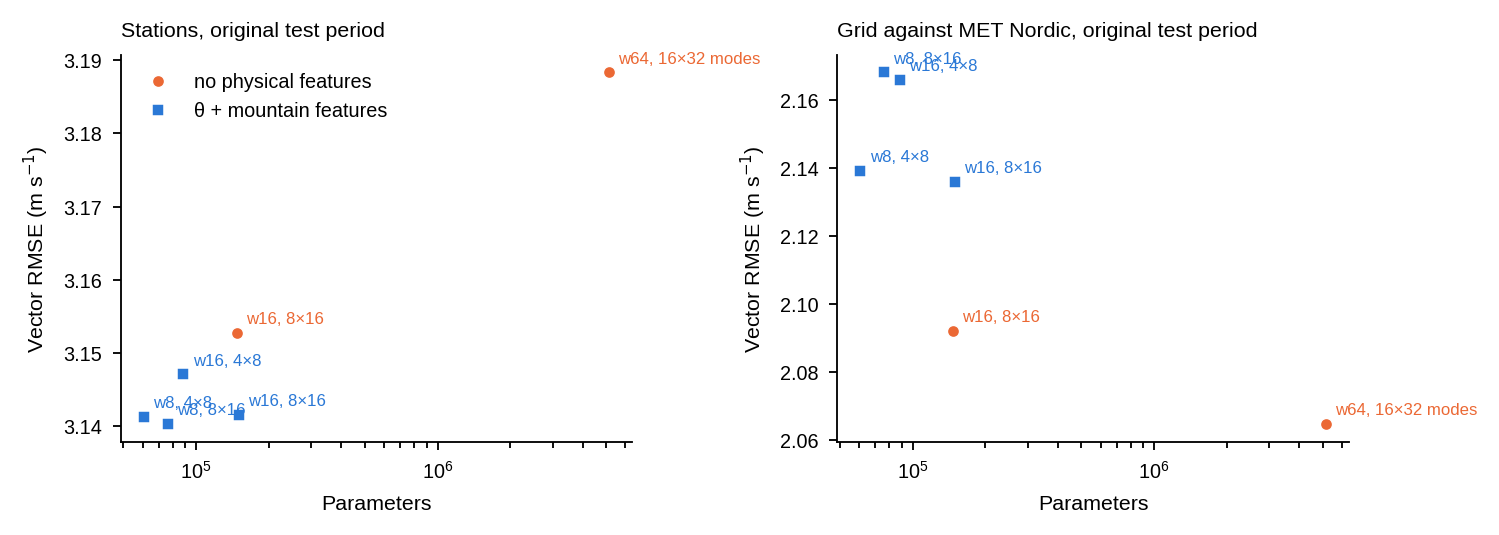

,parameters,seeds (orig / ext),original,extended,grid vs MET Nordic
encoder,,,,,
"w64, 16×32 modes",5140482,1 / 1,3.188,3.316,2.065
"w16, 8×16 (ours)",147234,3 / 3,3.153,3.256,2.092
"w16, 8×16 + θ/mtn",150050,3 / 3,3.142,3.255,2.136
"w16, 4×8 + θ/mtn",88610,1 / 0,3.147,NaN,2.166
"w8, 8×16 + θ/mtn",76114,1 / 0,3.140,NaN,2.168
"w8, 4×8 + θ/mtn",60754,1 / 0,3.141,NaN,2.139


In [8]:
S = D.SMALL
ENC = [  # label, run tag, physical features, name in grid_eval_all
    ('w64, 16×32 modes', 'rg60_rr10_z0_head-mlp', False, 'dual_mlp_gno'),
    ('w16, 8×16 (ours)', f'rg60_rr10_{S}_head-mlp', False, 'dual_small_mlp'),
    ('w16, 8×16 + θ/mtn', f'rg60_rr10_phys-all_{S}_head-mlp', True, 'dual_small_mlp_phys'),
    ('w16, 4×8 + θ/mtn', 'rg60_rr10_phys-all_r16m4x8_g16m4x8_z0_head-mlp', True, 'dual_w16m4x8_mlp_phys'),
    ('w8, 8×16 + θ/mtn', 'rg60_rr10_phys-all_r8m8x16_g8m8x16_z0_head-mlp', True, 'dual_w8m8x16_mlp_phys'),
    ('w8, 4×8 + θ/mtn', 'rg60_rr10_phys-all_r8m4x8_g8m4x8_z0_head-mlp', True, 'dual_w8m4x8_mlp_phys')]
rows, ENCF = [], {}
for lab, tag, phys, gk in ENC:
    fs = {per: d['P'].seeds(d['P'].dual, tag) for per, d in PER.items()}
    ENCF[lab] = fs
    s0 = min(fs['original'])
    r = {'encoder': lab, 'parameters': PER['original']['P'].n_params('dual', f'dual_sfno-fno_g0_s{s0}_{tag}_lr1e-05'),
         'seeds (orig / ext)': f"{len(fs['original'])} / {len(fs['extended'])}"}
    for per, d in PER.items():
        r[per] = np.mean([d['P'].rmse(f) for f in fs[per].values()]) if fs[per] else np.nan
    r['grid vs MET Nordic'] = float(np.sqrt(G[f'se_seed_{gk}'] / cnt.sum()).mean())
    rows.append(r)
enc = pd.DataFrame(rows).set_index('encoder')
enc.round(3).to_csv(FIG / 'encoder_size.csv')

fig, axs = plt.subplots(1, 2, figsize=(183 * MM, 58 * MM), gridspec_kw=dict(wspace=.4))
for ax, col, ttl in zip(axs, ['original', 'grid vs MET Nordic'],
                        ['Stations, original test period', 'Grid against MET Nordic, original test period']):
    for phys, c, mk, lab in [(False, ORANGE, 'o', 'no physical features'), (True, '#2a78d6', 's', 'θ + mountain features')]:
        e = enc[np.array([p_ for _, _, p_, _ in ENC]) == phys]
        ax.plot(e['parameters'], e[col], mk, color=c, ms=4, mec='white', mew=.5, label=lab, ls='')
        for name_, r in e.iterrows():
            ax.annotate(name_.split(' +')[0].replace(' (ours)', ''), (r['parameters'], r[col]), fontsize=5.5,
                        xytext=(3, 3), textcoords='offset points', color=c)
    ax.set_xscale('log'); ax.set_xlabel('Parameters'); ax.set_ylabel('Vector RMSE (m s$^{-1}$)')
    ax.set_title(ttl, fontsize=7, loc='left')
axs[0].legend(loc='upper left')
save(fig, 'fig4_encoder_size')
plt.show()
enc.round(3)

**Fig. 4 | Encoder size.** RMSE against the parameter count of the dual-scale GNO, at the stations
(left) and on the 1 km grid against MET Nordic (right), original test period; mean over the available
seeds.

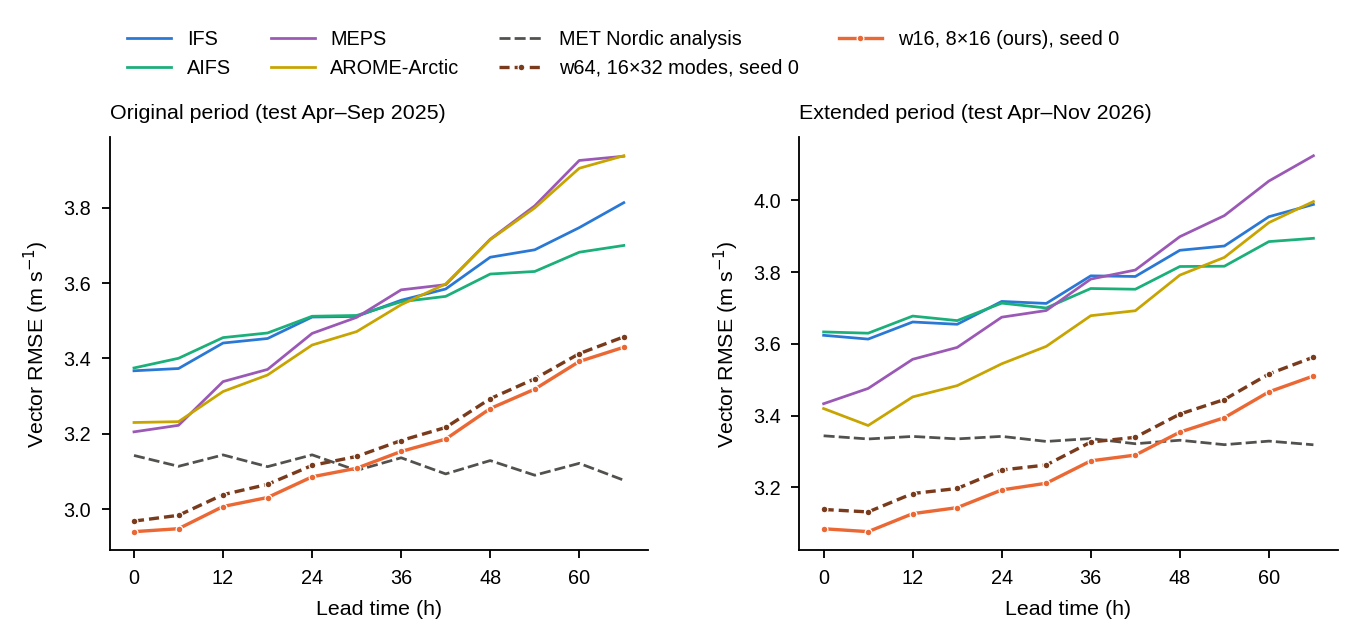

In [9]:
# by lead time per period: width 64 vs ours (seed 0 only for both, to compare like with like)
fig, axs = plt.subplots(1, 2, figsize=(183 * MM, 62 * MM), gridspec_kw=dict(wspace=.28))
for ax, (per, d) in zip(axs, PER.items()):
    for k in ['IFS', 'AIFS', 'MEPS', 'AROME-Arctic', 'MET Nordic analysis']:
        col, ls, mk = STYLE[k]
        ax.plot(LEADS, LEAD[per][k], color=col, ls=ls, lw=.9, label=k)
    for lab, c, ls in [('w64, 16×32 modes', '#7a3b1c', (0, (3, 1.5))), ('w16, 8×16 (ours)', ORANGE, '-')]:
        ax.plot(LEADS, d['P'].rmse_lead(ENCF[lab][per][0]), color=c, ls=ls, marker='o', ms=2.2,
                mec='white', mew=.4, lw=1.1, label=lab + ', seed 0')
    ax.set(xlabel='Lead time (h)', ylabel='Vector RMSE (m s$^{-1}$)', xticks=LEADS[::2])
    ax.set_title(PTITLE[per], fontsize=7, loc='left')
axs[0].legend(ncol=4, loc='lower left', bbox_to_anchor=(0, 1.1), handlelength=2.2)
save(fig, 'fig5_encoder_lead')
plt.show()